# Online Retail Sales Analysis
**Author:** Baron Kyaw · Python / Big Data practice project

Question: How do monthly transaction values, countries and products compare, and how much do cancellations change the picture?

Source: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), Chen, D. (2015), DOI **10.24432/C5BW33**, CC BY 4.0. Transactions cover 1 December 2010–9 December 2011; prices are in pounds sterling. This is a historical dataset, not a current business report.

Developed with AI assistance. Run each cell and review the assumptions before using the results. This notebook performs descriptive analysis, not machine learning.

In [1]:
from pathlib import Path
from io import BytesIO
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('data/Online_Retail.xlsx')
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
raw = pd.read_excel(DATA, engine='openpyxl')
print(f'{len(raw):,} rows; {len(raw.columns)} columns')
print(raw.dtypes.to_string())
print('\nMissing values:\n' + raw.isna().sum().to_string())
print(f'Exact duplicate rows: {raw.duplicated().sum():,}')
print(f'Date range: {raw.InvoiceDate.min()} to {raw.InvoiceDate.max()}')

541,909 rows; 8 columns
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Exact duplicate rows: 5,268
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


## 1. Cleaning and metric definitions
Remove exact repeated rows as an explicit assumption: there is no unique line identifier, so genuine repeated purchases cannot be ruled out. Keep the original file and report the effect of this choice. Missing customer IDs are retained for sales analysis.

Two views:
* **Positive purchase value:** positive quantity and price, excluding invoices beginning C. Refunds are not subtracted.
* **Signed transaction value:** quantity × price on positive-price rows with nonzero quantity. Negative quantities reduce this value. This is a descriptive balance of recorded lines, not audited accounting revenue or profit.

For product rankings exclude these explicit service/adjustment codes: POST, DOT, M, m, BANK CHARGES, AMAZONFEE, CRUK, C2, D, S, B. Other alphanumeric product codes remain. December 2011 has only nine days of coverage.

In [2]:
audit = []
dedup = raw.drop_duplicates().copy()
audit.append({'step':'Remove exact duplicate rows','removed':len(raw)-len(dedup),'remaining':len(dedup)})
dedup['InvoiceNo'] = dedup.InvoiceNo.astype(str)
dedup['StockCode'] = dedup.StockCode.astype(str)
cancel = dedup.InvoiceNo.str.startswith('C')
positive = dedup.copy()
for label, keep in [
    ('Exclude C cancellation invoices', ~cancel),
    ('Require positive quantity', dedup.Quantity.gt(0)),
    ('Require positive unit price', dedup.UnitPrice.gt(0)),
    ('Require description', dedup.Description.notna())
]:
    before = len(positive)
    positive = positive.loc[keep.reindex(positive.index)].copy()
    audit.append({'step':label,'removed':before-len(positive),'remaining':len(positive)})
positive['ValueGBP'] = positive.Quantity * positive.UnitPrice
signed = dedup.loc[dedup.UnitPrice.gt(0) & dedup.Quantity.ne(0)].copy()
signed['ValueGBP'] = signed.Quantity * signed.UnitPrice
service_codes = {'POST','DOT','M','m','BANK CHARGES','AMAZONFEE','CRUK','C2','D','S','B'}
merchandise = signed.loc[~signed.StockCode.isin(service_codes)].copy()
audit_table = pd.DataFrame(audit)
audit_table.to_csv(OUT/'cleaning_audit.csv', index=False)
purchase_value = positive.ValueGBP.sum()
negative_value = signed.loc[signed.Quantity.lt(0),'ValueGBP'].sum()
signed_value = signed.ValueGBP.sum()
pre_dedup_purchase = raw.loc[~raw.InvoiceNo.astype(str).str.startswith('C') & raw.Quantity.gt(0) & raw.UnitPrice.gt(0) & raw.Description.notna()]
duplicate_value_effect = (pre_dedup_purchase.Quantity * pre_dedup_purchase.UnitPrice).sum() - purchase_value
print(audit_table.to_string(index=False))
print(f'Positive purchase value: £{purchase_value:,.2f}')
print(f'Negative recorded value: £{negative_value:,.2f}')
print(f'Signed transaction value: £{signed_value:,.2f}')
print(f'Positive-value effect of duplicate removal: £{duplicate_value_effect:,.2f}')

                           step  removed  remaining
    Remove exact duplicate rows     5268     536641
Exclude C cancellation invoices     9251     527390
      Require positive quantity     1336     526054
    Require positive unit price     1176     524878
            Require description        0     524878
Positive purchase value: £10,642,110.80
Negative recorded value: £-893,979.73
Signed transaction value: £9,748,131.07
Positive-value effect of duplicate removal: £24,573.74


## 2. Monthly trend
Compare complete months separately from the final partial month. Positive purchase values and signed values answer different questions; plot both rather than hiding cancellations.

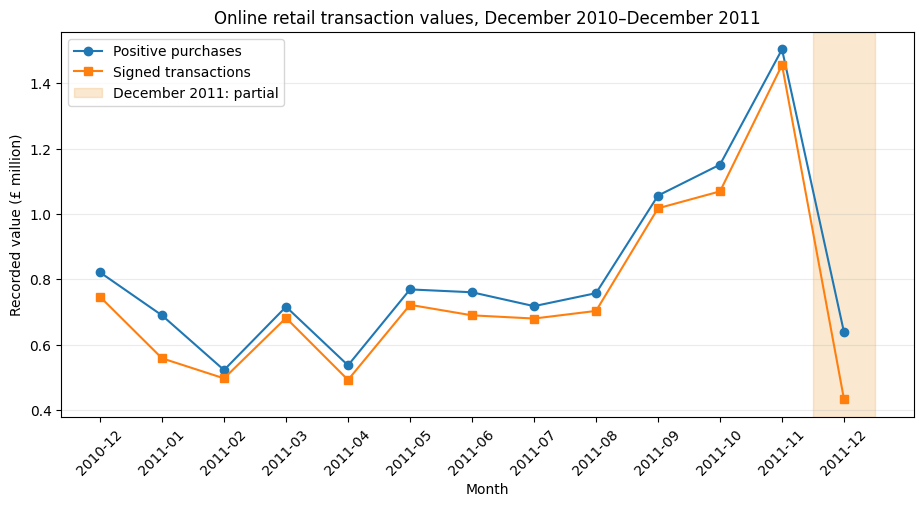

         PositivePurchaseGBP  SignedValueGBP  PartialMonth
Month                                                     
2010-12            821452.73       746723.61         False
2011-01            689811.61       558448.56         False
2011-02            522545.56       497026.41         False
2011-03            716215.26       682013.98         False
2011-04            536968.49       492367.84         False
2011-05            769296.61       722094.10         False
2011-06            760547.01       689977.23         False
2011-07            718076.12       680156.99         False
2011-08            757841.38       703510.58         False
2011-09           1056435.19      1017596.68         False
2011-10           1151263.73      1069368.23         False
2011-11           1503866.78      1456145.80         False
2011-12            637790.33       432701.06          True


In [3]:
positive['Month'] = positive.InvoiceDate.dt.to_period('M').astype(str)
signed['Month'] = signed.InvoiceDate.dt.to_period('M').astype(str)
monthly = pd.concat([
    positive.groupby('Month').ValueGBP.sum().rename('PositivePurchaseGBP'),
    signed.groupby('Month').ValueGBP.sum().rename('SignedValueGBP')
],axis=1).fillna(0)
monthly['PartialMonth'] = monthly.index == '2011-12'
monthly.to_csv(OUT/'monthly_sales.csv')

def save_chart(name):
    buffer = BytesIO()
    plt.savefig(buffer, format='png', dpi=150, bbox_inches='tight')
    (OUT/name).write_bytes(buffer.getvalue())
    plt.show()
    plt.close()

plt.figure(figsize=(11,5))
plt.plot(monthly.index, monthly.PositivePurchaseGBP/1e6, marker='o', label='Positive purchases')
plt.plot(monthly.index, monthly.SignedValueGBP/1e6, marker='s', label='Signed transactions')
plt.axvspan(11.5,12.5,color='#efb366',alpha=.3,label='December 2011: partial')
plt.ylabel('Recorded value (£ million)'); plt.xlabel('Month')
plt.title('Online retail transaction values, December 2010–December 2011')
plt.xticks(rotation=45); plt.legend(); plt.grid(axis='y',alpha=.25)
save_chart('monthly_sales.png')
print(monthly.round(2).to_string())

## 3. Countries and products
Country values include service and adjustment lines. Product rankings use merchandise codes and signed quantities/values so cancellations affect rankings. A description is chosen from the most common nonmissing description for each code; names can vary in the source.

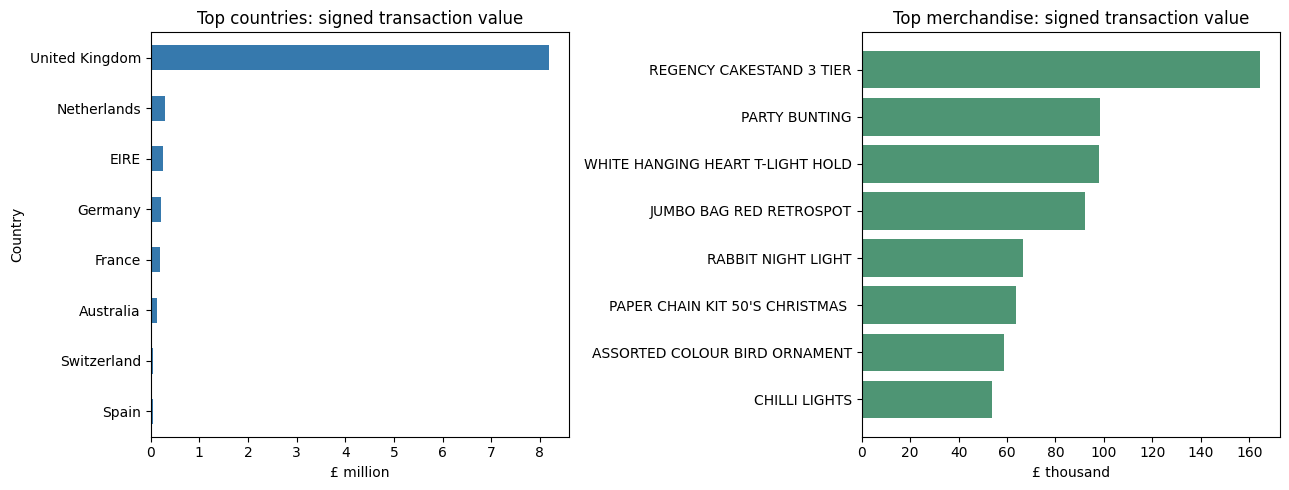

           SignedValueGBP  SignedUnits  DistinctInvoices                         Description
StockCode                                                                                   
22423           164459.49        12996              2168            REGENCY CAKESTAND 3 TIER
47566            98243.88        18006              1705                       PARTY BUNTING
85123A           97838.45        35063              2240  WHITE HANGING HEART T-LIGHT HOLDER
85099B           92175.79        47256              2132             JUMBO BAG RED RETROSPOT
23084            66661.63        30631              1009                  RABBIT NIGHT LIGHT
22086            63715.24        18876              1170     PAPER CHAIN KIT 50'S CHRISTMAS 
84879            58792.42        36282              1467       ASSORTED COLOUR BIRD ORNAMENT
79321            53746.66        10222               667                       CHILLI LIGHTS
22502            51023.52         1862               472          PICN

In [4]:
countries = signed.groupby('Country').agg(SignedValueGBP=('ValueGBP','sum'),Lines=('InvoiceNo','size')).sort_values('SignedValueGBP',ascending=False)
countries.to_csv(OUT/'country_sales.csv')
names = merchandise.dropna(subset=['Description']).groupby('StockCode').Description.agg(lambda s:s.value_counts().index[0])
products = merchandise.groupby('StockCode').agg(SignedValueGBP=('ValueGBP','sum'),SignedUnits=('Quantity','sum'),DistinctInvoices=('InvoiceNo','nunique')).join(names).sort_values('SignedValueGBP',ascending=False)
products.to_csv(OUT/'product_sales.csv')
fig, axes = plt.subplots(1,2,figsize=(13,5))
countries.head(8).iloc[::-1].SignedValueGBP.div(1e6).plot.barh(ax=axes[0],color='#3679ad')
axes[0].set_title('Top countries: signed transaction value'); axes[0].set_xlabel('£ million')
top = products.head(8).iloc[::-1]
axes[1].barh(top.Description.str.slice(0,32),top.SignedValueGBP/1000,color='#4e9574')
axes[1].set_title('Top merchandise: signed transaction value'); axes[1].set_xlabel('£ thousand')
plt.tight_layout(); save_chart('countries_and_products.png')
print(products.head(10).round(2).to_string())
print('\nCancellation example:')
print(signed.loc[signed.StockCode.eq('23843'),['InvoiceNo','InvoiceDate','Quantity','ValueGBP']].to_string(index=False))

## 4. Customers with known IDs
Recency is days since the last positive purchase, measured on 10 December 2011. Frequency counts distinct purchase invoices, not rows. Monetary value is positive purchase value, without subtracting returns. Anonymous purchases stay in overall sales but cannot be attributed to a customer.

Repeat buyer means at least two distinct positive purchase invoices in this observation window. These are descriptive measures, not predictions of retention.

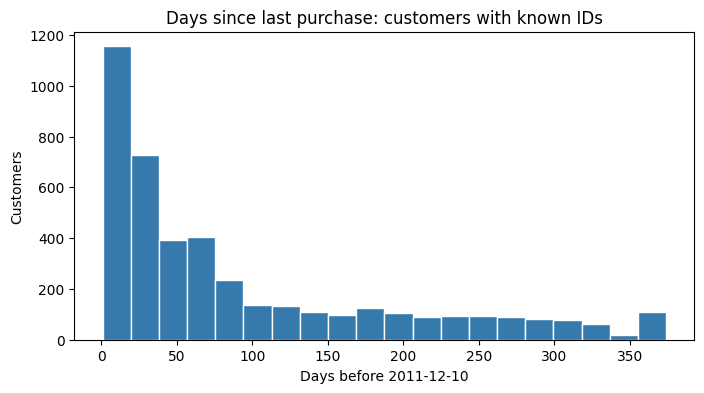

Known customers: 4,338
Repeat buyers among known IDs: 65.6%
Positive purchase value with missing customer IDs: 16.5%
Top 434 customers (rounded-up top 10%) share of known-customer purchases: 61.5%


In [5]:
known = positive.dropna(subset=['CustomerID']).copy()
reference = positive.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
customers = known.groupby('CustomerID').agg(LastPurchase=('InvoiceDate','max'),Frequency=('InvoiceNo','nunique'),MonetaryGBP=('ValueGBP','sum'))
customers['RecencyDays'] = (reference-customers.LastPurchase.dt.normalize()).dt.days
customers.index = customers.index.astype('int64')
customers.to_csv(OUT/'customer_summary.csv')
repeat_share = customers.Frequency.ge(2).mean()
anonymous_value = positive.loc[positive.CustomerID.isna(),'ValueGBP'].sum()
anonymous_share = anonymous_value/purchase_value
top_count = max(1,int(np.ceil(len(customers)*.10)))
top_customer_share = customers.MonetaryGBP.nlargest(top_count).sum()/customers.MonetaryGBP.sum()
print(f'Known customers: {len(customers):,}')
print(f'Repeat buyers among known IDs: {repeat_share:.1%}')
print(f'Positive purchase value with missing customer IDs: {anonymous_share:.1%}')
print(f'Top {top_count:,} customers (rounded-up top 10%) share of known-customer purchases: {top_customer_share:.1%}')
plt.figure(figsize=(8,4))
plt.hist(customers.RecencyDays,bins=20,color='#3679ad',edgecolor='white')
plt.title('Days since last purchase: customers with known IDs')
plt.xlabel(f'Days before {reference.date()}'); plt.ylabel('Customers')
save_chart('customer_recency.png')

## 5. Validation and limits
Check row reconciliation and totals using different aggregations. Currency totals retain source price precision; displays round to two decimals. Checks use a tiny tolerance for floating-point arithmetic.

Limits: one historical retailer, partial December 2011, missing customer IDs, uncertain exact duplicates, no costs or profit, no causal explanation, and no guarantee that every negative line matches a purchase in this date range. A cancelled order can also affect customer purchase measures because those measures deliberately use the positive view.

In [6]:
assert sum(a['removed'] for a in audit) + len(positive) == len(raw)
assert positive.Quantity.gt(0).all() and positive.UnitPrice.gt(0).all()
assert not positive.InvoiceNo.str.startswith('C').any()
assert not dedup.duplicated().any()
assert np.isclose(monthly.PositivePurchaseGBP.sum(), purchase_value, rtol=0, atol=1e-6)
assert np.isclose(monthly.SignedValueGBP.sum(), signed_value, rtol=0, atol=1e-6)
assert np.isclose(countries.SignedValueGBP.sum(), signed_value, rtol=0, atol=1e-6)
assert np.isclose(products.SignedValueGBP.sum(), merchandise.ValueGBP.sum(), rtol=0, atol=1e-6)
assert np.isclose(customers.MonetaryGBP.sum()+anonymous_value,purchase_value,rtol=0,atol=1e-6)
assert customers.Frequency.sum() == known[['CustomerID','InvoiceNo']].drop_duplicates().shape[0]
assert customers.RecencyDays.ge(0).all()
complete = monthly.loc[~monthly.PartialMonth]
summary = {
    'source_rows':len(raw), 'positive_rows':len(positive),
    'positive_purchase_gbp':float(purchase_value),'signed_value_gbp':float(signed_value),
    'negative_value_gbp':float(negative_value),'duplicate_value_effect_gbp':float(duplicate_value_effect),
    'peak_complete_month':complete.SignedValueGBP.idxmax(),
    'peak_complete_month_signed_gbp':float(complete.SignedValueGBP.max()),
    'uk_share_signed_value':float(countries.loc['United Kingdom','SignedValueGBP']/signed_value),
    'known_customers':len(customers),'repeat_buyer_share':float(repeat_share),
    'anonymous_purchase_share':float(anonymous_share),'top_10pct_customer_share':float(top_customer_share),
    'top_product_code':str(products.index[0]),'top_product_name':str(products.iloc[0].Description),
    'top_product_signed_gbp':float(products.iloc[0].SignedValueGBP)
}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('All 11 validation checks passed.')
print(json.dumps(summary,indent=2))

All 11 validation checks passed.
{
  "source_rows": 541909,
  "positive_rows": 524878,
  "positive_purchase_gbp": 10642110.804000001,
  "signed_value_gbp": 9748131.074,
  "negative_value_gbp": -893979.73,
  "duplicate_value_effect_gbp": 24573.73999999836,
  "peak_complete_month": "2011-11",
  "peak_complete_month_signed_gbp": 1456145.8,
  "uk_share_signed_value": 0.8400843445614097,
  "known_customers": 4338,
  "repeat_buyer_share": 0.6558321807284463,
  "anonymous_purchase_share": 0.1649016762107375,
  "top_10pct_customer_share": 0.6145208192064806,
  "top_product_code": "22423",
  "top_product_name": "REGENCY CAKESTAND 3 TIER",
  "top_product_signed_gbp": 164459.49
}


## What I would do next
Investigate unmatched cancellations and high-value orders before making business recommendations. Compare duplicate-removal assumptions. With reliable customer linkage, build a time-based holdout for a prediction task rather than reporting training performance as a result.